
# 01 · Preprocessing — Bischoff 2021 LUAD (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven multiplicative
gap**, integrate patients (Harmony), embed, and annotate the malignant
transcriptional states. Bischoff et al. profile early-stage lung adenocarcinoma
(LUAD); the malignant compartment is organised by a **continuous alveolar
differentiation axis** — an alveolar/AT2-like differentiated pole grading into a
dedifferentiated/secretory pole — rather than by discrete subtypes (Puram 2017,
four HNSCC subtypes around a *Mixed* hub) or by a cycling-vs-embryonic split
(Kürten 2021). There is therefore **no lobe to remove**: the whole malignant
manifold carries the trajectory analysed in 02–04.

Every tunable choice is *re-derived from this dataset*, not inherited — in
particular Harmony `theta` and the number of PCs differ from Kürten. Deliverable:
`processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Bischoff2021_Lung | category: Lung



### Load malignant compartment
Bischoff et al. annotate cell type directly; we take their `Malignant` calls
(the loader normalises UMI counts to median library size and log1p-transforms).

In [3]:
from scripts.load import load_CCCA_adata
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())

Loading ../../../../../../data/unzip/CCCA/Data_Bischoff2021_Lung
Done.
full atlas: (120961, 33514)
malignant: (13439, 33514) | samples: 19



### Sample thresholding — derived by multiplicative gap-finding
Malignant calls in the CD45⁺/normal-adjacent fractions are spillover specks. Rather
than a round-number cut, find the largest **multiplicative** cliff in the sorted
per-sample counts and cut at its geometric mean — the natural separatrix between
tumour-bearing samples and spillover.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [3934 3544 1681 1638  748  624  406  358  322  127   15   15    8    6
    4    3    2    2    2]
largest gap: 127 -> 15 (ratio 8.47)
derived threshold (geometric mean across the gap) = 43
kept 10/19 samples -> 13382 cells



### Overdispersion, PCA, Harmony integration, embedding — parameters derived here
Two constants are re-derived from Bischoff, both differing from Kürten:

- **`n_pcs = 12`** — the scree knee. Malignant LUAD variance is concentrated in the
  first ~12 PCs (PC1 alone ≈ 12%), steeper than Kürten (20) or Puram (40), so 12
  captures the structure without trailing into patient/CNV noise.
- **`theta = 2`** — chosen by a same-sample-neighbour-fraction sweep (θ 2/5/10) read
  in the *downstream* 12-PC space. Malignant cells are CNV-driven and patient-specific,
  so unintegrated they form one island per patient (same-sample fraction ≈ 0.97). θ=2
  collapses this toward the mixing floor while preserving the differentiation biology;
  higher θ over-integrates into a featureless blob. This is deliberately **lower** than
  Kürten's θ=10 — the assumption that a single θ transfers across datasets does not hold.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
sce.pp.harmony_integrate(adata, 'sample', theta=2, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=12, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1976 over-dispersed features (0:00:04) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1976



### Manifold continuity — kNN connectivity (no island removal)
Kürten strips detached specks with a UMAP **radius**-graph. Here that step is
**not** applied: on this continuous differentiation strip the radius graph fragments
the two poles into comparably-sized blobs (a visualisation artefact), yet the
**kNN graph the trajectory actually traverses is a single connected component**.
Removing 'islands' would discard ~40% of real malignant cells. Continuity is
therefore certified on the kNN graph, and **all cells are retained**.

In [6]:
ncomp, lab = connected_components(adata.obsp['connectivities'], directed=False)
sizes = pd.Series(lab).value_counts().values
print(f'kNN graph connected components: {ncomp} | component sizes: {sizes.tolist()}')
assert ncomp == 1, 'manifold is not a single kNN component'
print('single connected kNN component -> continuous manifold, all cells retained')

kNN graph connected components: 1 | component sizes: [13382]
single connected kNN component -> continuous manifold, all cells retained



### Malignant-state annotation (data-driven, biology-labelled)
Low-resolution Leiden (res=0.15) recovers the coarse structure of the strip. Label
each cluster **by biology**, not by Leiden index, from three LUAD marker-score
programmes: alveolar/AT2 differentiation (SFTPC/SFTPB/SFTPA1-2/NAPSA/NKX2-1),
secretory/club (SCGB/MUC/AQP5/MSLN), and a dedifferentiated pole (low differentiation
markers, glycolytic/keratin). `cell_cycle_phase` comes from the loader's phase calls;
note Bischoff has **no distinct cycling compartment** (only a scattered minority),
which is why the trajectory is not split off a cycling lobe as in Kürten.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='state_raw', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
sets = {'Alveolar/AT2':['SFTPC','SFTPB','SFTPA1','SFTPA2','NAPSA','NKX2-1','SCGB3A2'],
        'Secretory/club':['SCGB3A1','SCGB1A1','MUC5B','MUC5AC','AQP5','MSLN'],
        'Dedifferentiated':['KRT8','KRT18','KRT19','KRT7','PKM','LDHA','VIM']}
for k,gs in sets.items():
    sc.tl.score_genes(adata, [g for g in gs if g in adata.var_names], score_name=k, random_state=SEED)
prof = adata.obs.groupby('state_raw', observed=True)[list(sets)].mean()
print('per-cluster mean state scores:'); print(prof.round(3).to_string())
def call_state(row):
    if row['Alveolar/AT2'] < 0.5 and row['Secretory/club'] < 0.5:
        return 'Dedifferentiated'
    return 'Alveolar/AT2' if row['Alveolar/AT2'] >= row['Secretory/club'] else 'Secretory/club'
lab_map = {c: call_state(prof.loc[c]) for c in prof.index}
adata.obs['state'] = adata.obs['state_raw'].map(lab_map).astype('category')
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('cluster -> state:', lab_map)
print('state sizes:', adata.obs['state'].value_counts().to_dict())
print(f'cycling fraction (whole manifold): {adata.obs["cycling"].mean():.3f}')

per-cluster mean state scores:
           Alveolar/AT2  Secretory/club  Dedifferentiated
state_raw                                                
0                 1.075           0.947            -0.223
1                 0.235           0.251             0.195
2                 0.695           1.195            -0.172
cluster -> state: {'0': 'Alveolar/AT2', '1': 'Dedifferentiated', '2': 'Secretory/club'}
state sizes: {'Dedifferentiated': 7448, 'Alveolar/AT2': 4173, 'Secretory/club': 1761}
cycling fraction (whole manifold): 0.052



### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The
same-sample-neighbour fraction quantifies mixing (1.0 = perfect patient islands,
≈0.2 = well-mixed null); visual confirmation follows in `samples.pdf`.

In [8]:
from sklearn.neighbors import NearestNeighbors
k = 30
nn = NearestNeighbors(n_neighbors=k+1).fit(adata.obsm['X_pca_harmony'][:, :12])
_, idx = nn.kneighbors(adata.obsm['X_pca_harmony'][:, :12])
s = adata.obs['sample'].values
ssf = np.mean([(s[idx[i,1:]] == s[i]).mean() for i in range(len(s))])
print(f'{adata.obs["sample"].nunique()} samples on one continuous kNN manifold')
print(f'same-sample-neighbour fraction (integrated) = {ssf:.3f}  (unintegrated ~0.97, mixing null ~0.20)')
print('Gate 1: samples intermixed on one continuous manifold -> GO')

10 samples on one continuous kNN manifold
same-sample-neighbour fraction (integrated) = 0.441  (unintegrated ~0.97, mixing null ~0.20)
Gate 1: samples intermixed on one continuous manifold -> GO


### Save processed data

In [9]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (13382, 24764)



### Sample-integration figure (deliverable)
House style: `figsize=(3.5,1.5)` horizontal strip, `size=30`, colour = sample.
Orientation uses the fixed house transform derived in 02 (pseudotime left→right);
here direction is immaterial for this categorical panel. Intermixing across the
strip is the Gate-1 batch-integration evidence.

saved samples.pdf | cells: 13382


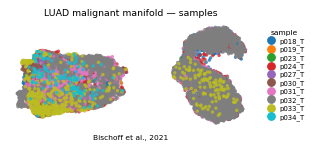

In [10]:
# orient to a horizontal strip: pick the raw UMAP axis most aligned with the
# differentiation axis (alveolar score) as horizontal. No rotation/interpolation.
alv = adata.obs['Alveolar/AT2'].values
xy = adata.obsm['X_umap'].astype(float)
cx = abs(np.corrcoef(xy[:,0], alv)[0,1]); cy = abs(np.corrcoef(xy[:,1], alv)[0,1])
if cx >= cy:
    xlin = np.column_stack([xy[:,0]*np.sign(np.corrcoef(xy[:,0],alv)[0,1]), xy[:,1]])
else:
    xlin = np.column_stack([xy[:,1]*np.sign(np.corrcoef(xy[:,1],alv)[0,1]), -xy[:,0]])
plot = adata.copy(); plot.obsm['X_umap'] = xlin
xl = xlin; xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('LUAD malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Bischoff et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', adata.shape[0])